# Music-Taste: exploración y recomendador por similitud de audio

**Flujo:** carga → auditoría de calidad → limpieza → EDA → escalado → recomendador (cosine similarity).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

DATA_DIR = "../data"
BOUNDARY = 68  # popularidad en la frontera entre los datasets High y Low

AUDIO_COLS = [
    "energy",
    "tempo",
    "danceability",
    "loudness",
    "liveness",
    "valence",
    "speechiness",
    "instrumentalness",
    "acousticness",
]
INT_COLS = ["time_signature", "mode", "key", "duration_ms"]
INFO_COLS = ["track_name", "track_artist", "playlist_genre"]

## 1. Carga de datos

In [2]:
high = pd.read_csv(f"{DATA_DIR}/high_popularity_spotify_data.csv")
low = pd.read_csv(f"{DATA_DIR}/low_popularity_spotify_data.csv")
datasets = {"High": high, "Low": low}

In [3]:
for name, df in datasets.items():
    print(f"=== {name}: {df.shape[0]} filas x {df.shape[1]} columnas ===")
    df.info()
    print()

=== High: 1686 filas x 29 columnas ===
<class 'pandas.DataFrame'>
RangeIndex: 1686 entries, 0 to 1685
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   energy                    1686 non-null   float64
 1   tempo                     1686 non-null   float64
 2   danceability              1686 non-null   float64
 3   playlist_genre            1686 non-null   str    
 4   loudness                  1686 non-null   float64
 5   liveness                  1686 non-null   float64
 6   valence                   1686 non-null   float64
 7   track_artist              1686 non-null   str    
 8   time_signature            1686 non-null   int64  
 9   speechiness               1686 non-null   float64
 10  track_popularity          1686 non-null   int64  
 11  track_href                1686 non-null   str    
 12  uri                       1686 non-null   str    
 13  track_album_name          1685 non-

In [4]:
high.head()

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.122,0.535,"Lady Gaga, Bruno Mars",3,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0,6,251668,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.117,0.438,Billie Eilish,4,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1,2,210373,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.159,0.372,Gracie Abrams,4,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1,1,166300,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.304,0.786,Sabrina Carpenter,4,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0,0,157280,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.355,0.939,"ROSÉ, Bruno Mars",4,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0,0,169917,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M


In [5]:
low.head()

,time_signature,track_popularity,speechiness,danceability,playlist_name,track_artist,duration_ms,energy,playlist_genre,playlist_subgenre,...,track_album_id,playlist_id,track_id,valence,key,tempo,loudness,acousticness,liveness,track_album_name
0,4.0,23,0.0393,0.636,Rock Classics,Creedence Clearwater Revival,138053.0,0.746,rock,classic,...,4A8gFwqd9jTtnsNwUu3OQx,37i9dQZF1DWXRqgorJj26U,5e6x5YRnMJIKvYpZxLqdpH,0.432,0.0,132.310,-3.785,0.0648,0.1730,The Long Road Home - The Ultimate John Fogerty...
1,4.0,53,0.0317,0.572,Rock Classics,Van Halen,241600.0,0.835,rock,classic,...,2c965LEDRNrXXCeBOAAwns,37i9dQZF1DWXRqgorJj26U,5FqYA8KfiwsQvyBI4IamnY,0.795,0.0,129.981,-6.219,0.1710,0.0702,The Collection
2,4.0,55,0.0454,0.591,Rock Classics,Stevie Nicks,329413.0,0.804,rock,classic,...,3S404OgKoVQSJ3xXrDVlp8,37i9dQZF1DWXRqgorJj26U,5LNiqEqpDc8TuqPy79kDBu,0.658,0.0,111.457,-7.299,0.3270,0.0818,Bella Donna (Deluxe Edition)
3,4.0,64,0.1010,0.443,Jazz Classics,"Ella Fitzgerald, Louis Armstrong",185160.0,0.104,jazz,classic,...,1y5KGkUKO0NG32MhIIagCA,37i9dQZF1DXbITWG1ZJKYt,78MI7mu1LV1k4IA2HzKmHe,0.394,0.0,76.474,-17.042,0.9130,0.1910,"Love, Ella"
4,4.0,62,0.0298,0.685,Jazz Classics,Galt MacDermot,205720.0,0.472,jazz,classic,...,6f4b9wVTkKAf096k4XG6x5,37i9dQZF1DXbITWG1ZJKYt,6MN6yRVriszuyAVlyF8ndB,0.475,9.0,80.487,-9.691,0.7850,0.2240,Shapes of Rhythm/Woman Is Sweeter


## 2. Auditoría de calidad

### 2.1 Duplicados dentro de cada dataset

In [6]:
pd.DataFrame(
    {
        name: {
            "filas": len(df),
            "track_id duplicados (filas extra)": df["track_id"].duplicated().sum(),
            "track_id distintos repetidos": (df["track_id"].value_counts() > 1).sum(),
            "filas con track_name repetido": df.duplicated(
                subset="track_name", keep=False
            ).sum(),
        }
        for name, df in datasets.items()
    }
)

,High,Low
filas,1686,3145
track_id duplicados (filas extra),249,44
track_id distintos repetidos,213,44
filas con track_name repetido,502,177


In [7]:
def mismo_nombre(df):
    """Filas que comparten track_name (pueden ser tracks distintos con el mismo título)."""
    dup = df[df.duplicated(subset="track_name", keep=False)]
    return dup[["track_name", "track_artist", "track_id"]].sort_values("track_name")


def columnas_que_difieren(df, track_id=None):
    """Para un track_id repetido, muestra qué columnas cambian entre sus filas.
    Si no se pasa track_id, usa el primero que esté repetido."""
    if track_id is None:
        repetidos = df.loc[df["track_id"].duplicated(keep=False), "track_id"]
        if repetidos.empty:
            return None
        track_id = repetidos.iloc[0]
    filas = df[df["track_id"] == track_id]
    return filas.loc[:, filas.nunique() > 1]

In [8]:
mismo_nombre(high)

,track_name,track_artist,track_id
43,+57,"KAROL G, Feid, DFZM, Ovy On The Drums, J Balvi...",3mg9jYNC1NihbthlglzrWP
273,+57,"KAROL G, Feid, DFZM, Ovy On The Drums, J Balvi...",3mg9jYNC1NihbthlglzrWP
1317,+57,"KAROL G, Feid, DFZM, Ovy On The Drums, J Balvi...",3mg9jYNC1NihbthlglzrWP
211,3 Headed Goat (feat. Lil Baby & Polo G),"Lil Durk, Lil Baby, Polo G",6Tguhaf2uAe6OjRLsR2Tql
777,3 Headed Goat (feat. Lil Baby & Polo G),"Lil Durk, Lil Baby, Polo G",6Tguhaf2uAe6OjRLsR2Tql
...,...,...,...
554,née-nah,"21 Savage, Travis Scott, Metro Boomin",2yUzr8Sr6ldG8vmHhZwTnz
191,née-nah,"21 Savage, Travis Scott, Metro Boomin",2yUzr8Sr6ldG8vmHhZwTnz
725,we can't be friends (wait for your love),Ariana Grande,51ZQ1vr10ffzbwIjDCwqm4
31,we can't be friends (wait for your love),Ariana Grande,46kspZSY3aKmwQe7O77fCC


In [9]:
mismo_nombre(low)

,track_name,track_artist,track_id
87,AZAMAN,Rema,4K5lYtD8r6OFRbzWc6MwCS
421,AZAMAN,Rema,4K5lYtD8r6OFRbzWc6MwCS
1056,Albaizyn,lorleaf,3Qj2ViqEZ2niYq4s8R4Xyw
183,Albaizyn,lorleaf,3Qj2ViqEZ2niYq4s8R4Xyw
2597,Ani Maamin,DJ Kraz,4rUpJVSmkIZhXYJK9QpEzh
...,...,...,...
1277,glow,"Fred again.., Duskus, Four Tet, Joy Anonymous,...",3i9QKRl5Ql3pgUfNdYBVTc
1013,letting go,mood.,4PCMttKgDScL8IbN59lF11
1648,letting go,"Fireboy DML, Lojay",4VmZWEvWcmWFqg7GciQM88
1176,Éphémère,Tony Anderson,4LurYqydfPdLc9IN7eQxTF


In [10]:
display(columnas_que_difieren(high))
display(columnas_que_difieren(low))

,playlist_genre,playlist_name,playlist_subgenre,playlist_id
0,pop,Today's Top Hits,mainstream,37i9dQZF1DXcBWIGoYBM5M
455,gaming,Top Gaming Tracks,modern,37i9dQZF1DWTyiBJ6yEqeu
676,pop,Global Top 50,global,37i9dQZEVXbMDoHDwVN2tF


,playlist_name,playlist_subgenre,playlist_id
30,Classical Essentials,essential,37i9dQZF1DWWEJlAGA9gs0
2364,Neo-Classical,neo-classical,37i9dQZF1EIfnkSMcirbYT


### 2.2 Solapamiento entre High y Low

In [11]:
low_max = low["track_popularity"].max()
high_min = high["track_popularity"].min()

print(f"Máxima popularidad en Low: {low_max}")
print(f"Mínima popularidad en High: {high_min}")
print(
    f"Canciones de Low con popularidad >= {high_min}: {(low['track_popularity'] >= high_min).sum()}"
)
print(
    f"Canciones con popularidad == {BOUNDARY}: "
    f"Low={(low['track_popularity'] == BOUNDARY).sum()}, "
    f"High={(high['track_popularity'] == BOUNDARY).sum()}"
)

Máxima popularidad en Low: 68
Mínima popularidad en High: 68
Canciones de Low con popularidad >= 68: 45
Canciones con popularidad == 68: Low=45, High=124


In [12]:
shared_ids = set(high["track_id"]) & set(low["track_id"])
shared_boundary = set(low.loc[low["track_popularity"] == BOUNDARY, "track_id"]) & set(
    high.loc[high["track_popularity"] == BOUNDARY, "track_id"]
)

print(f"track_id compartidos entre High y Low: {len(shared_ids)}")
print(f"  de ellos, con popularidad {BOUNDARY} en ambos: {len(shared_boundary)}")

track_id compartidos entre High y Low: 43
  de ellos, con popularidad 68 en ambos: 43


In [13]:
# Ejemplo: misma canción en ambos datasets, lado a lado
if shared_ids:
    ejemplo = next(iter(shared_boundary or shared_ids))
    comparacion = pd.concat(
        [
            high[high["track_id"] == ejemplo].iloc[0],
            low[low["track_id"] == ejemplo].iloc[0],
        ],
        axis=1,
    )
    comparacion.columns = ["High", "Low"]
    display(comparacion)

,High,Low
energy,0.576,0.576
tempo,166.162,166.162
danceability,0.77,0.77
playlist_genre,arabic,arabic
loudness,-11.845,-11.845
liveness,0.08,0.08
valence,0.364,0.364
track_artist,Polo G,Polo G
time_signature,4,4.0
speechiness,0.339,0.339


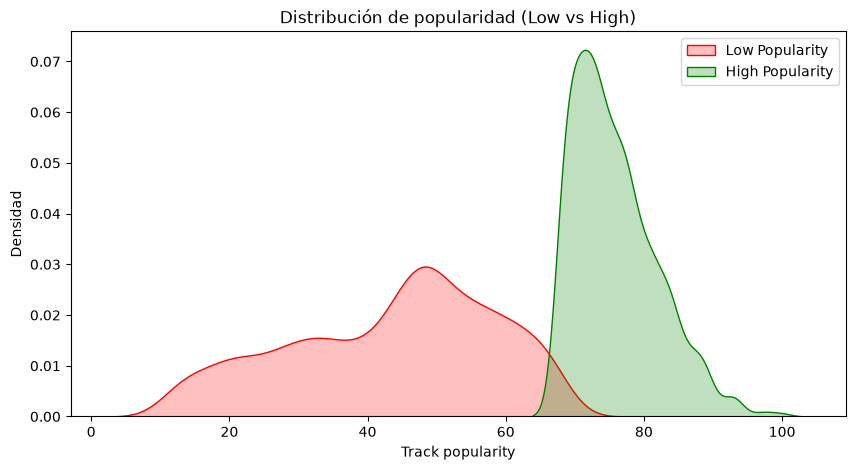

In [14]:
plt.figure(figsize=(10, 5))
sns.kdeplot(low["track_popularity"], label="Low Popularity", fill=True, color="red")
sns.kdeplot(high["track_popularity"], label="High Popularity", fill=True, color="green")
plt.title("Distribución de popularidad (Low vs High)")
plt.xlabel("Track popularity")
plt.ylabel("Densidad")
plt.legend()
plt.show()

### 2.3 Valores nulos

In [15]:
# Filas de Low con nulos en las features de audio
nulos = low[low[AUDIO_COLS].isnull().any(axis=1)]
print(f"Filas con nulos en features de audio: {len(nulos)}")
nulos[["track_id", "id"]]

Filas con nulos en features de audio: 1


,track_id,id
263,2teI76KKFE6qkpLZJs7tZ7,NaN


## 3. Limpieza

Se unen ambos datasets, se descartan filas sin features de audio y se deduplica en dos pasos: primero por `track_id` y luego por `track_name` + `track_artist`, ya que una misma canción puede aparecer con distinto `track_id` (por ejemplo, como single y como parte de un álbum). El orden importa: `High` va primero en el `concat`, así que con `keep="first"` las canciones compartidas se quedan con su versión de High.

In [16]:
df_clean = (
    pd.concat([high, low], ignore_index=True)
    .dropna(subset=AUDIO_COLS)
    .drop_duplicates(subset="track_id", keep="first")
    .drop_duplicates(subset=["track_name", "track_artist"], keep="first")
    .reset_index(drop=True)
)
df_clean[INT_COLS] = df_clean[INT_COLS].astype("int64")

print(f"Shape: {df_clean.shape}")
print("Columnas con nulos:")
print(df_clean.isnull().sum().loc[lambda s: s > 0])

Shape: (4465, 29)
Columnas con nulos:
track_album_name    1
dtype: int64


In [17]:
df_clean[INT_COLS].dtypes

time_signature    int64
mode              int64
key               int64
duration_ms       int64
dtype: object

## 4. EDA de features de audio

In [18]:
df_clean[AUDIO_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
energy,4465.0,0.579001,0.250357,0.000202,0.4230,0.626000,0.773,0.998
tempo,4465.0,118.264799,28.708546,48.232000,96.0230,118.174000,137.129,241.426
danceability,4465.0,0.620426,0.189771,0.058900,0.5220,0.653000,0.757,0.979
loudness,4465.0,-9.505803,7.304178,-48.069000,-10.6150,-7.311000,-5.395,1.318
liveness,4465.0,0.168074,0.125454,0.021000,0.0955,0.117000,0.196,0.979
valence,4465.0,0.478440,0.259592,0.029600,0.2660,0.479000,0.688,0.987
speechiness,4465.0,0.100500,0.100587,0.021900,0.0384,0.055100,0.115,0.927
instrumentalness,4465.0,0.213179,0.359770,0.000000,0.0000,0.000119,0.307,0.991
acousticness,4465.0,0.352019,0.329223,0.000004,0.0567,0.240000,0.617,0.996


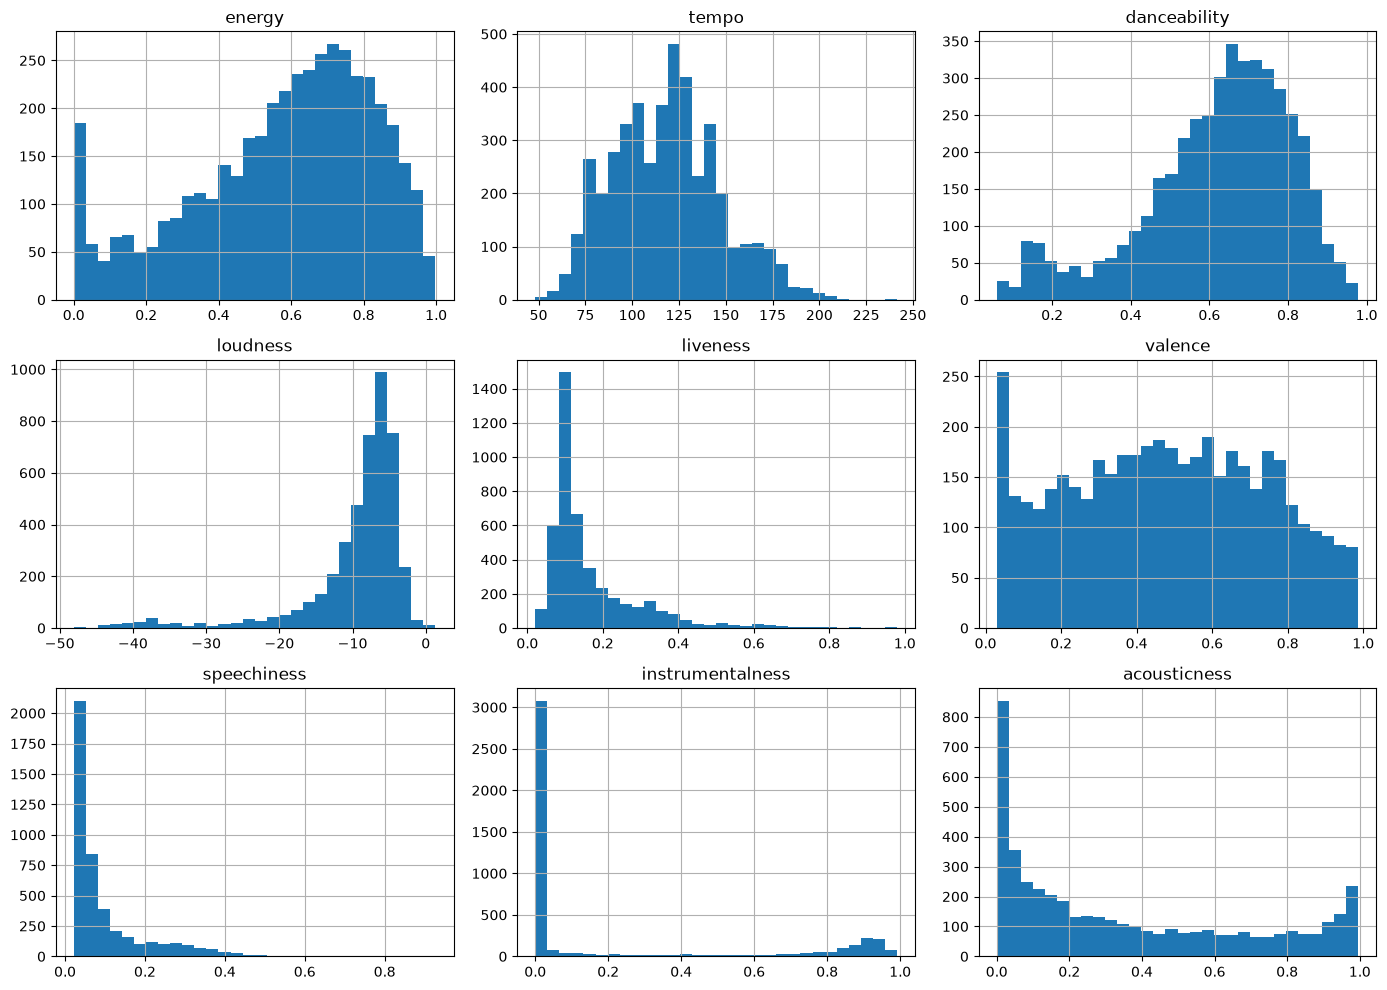

In [19]:
df_clean[AUDIO_COLS].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

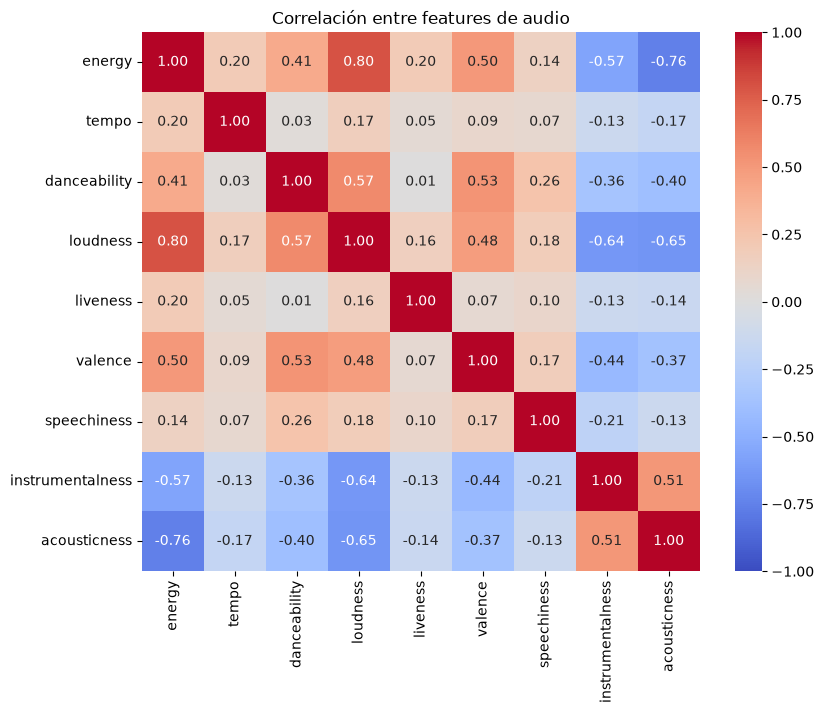

In [20]:
corr_matrix = df_clean[AUDIO_COLS].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlación entre features de audio")
plt.show()

## 5. Escalado

Z-score por feature, para que `tempo` y `loudness` (escalas grandes) no dominen la similitud.

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[AUDIO_COLS])

# Sanity check: media ~0 y desviación ~1 en cada columna
pd.DataFrame(
    {"mean": X_scaled.mean(axis=0), "std": X_scaled.std(axis=0)},
    index=AUDIO_COLS,
).round(2)

,mean,std
energy,0.0,1.0
tempo,-0.0,1.0
danceability,0.0,1.0
loudness,0.0,1.0
liveness,-0.0,1.0
valence,0.0,1.0
speechiness,0.0,1.0
instrumentalness,0.0,1.0
acousticness,-0.0,1.0


In [22]:
# Ejemplo: primera canción, valores originales vs. escalados
print(df_clean.loc[0, ["track_name", "track_artist"]].to_dict())
pd.DataFrame(
    {
        "Original": df_clean.loc[0, AUDIO_COLS],
        "Escalado (Z-score)": X_scaled[0].round(2),
    }
)

{'track_name': 'Die With A Smile', 'track_artist': 'Lady Gaga, Bruno Mars'}


,Original,Escalado (Z-score)
energy,0.5920,0.05
tempo,157.9690,1.38
danceability,0.5210,-0.52
loudness,-7.7770,0.24
liveness,0.1220,-0.37
valence,0.5350,0.22
speechiness,0.0304,-0.70
instrumentalness,0.0000,-0.59
acousticness,0.3080,-0.13


## 6. Recomendador por similitud coseno

La similitud se calcula solo contra la canción consultada (O(n)), no con la matriz completa n×n.

In [23]:
def buscar_cancion(texto):
    """Busca por artista o nombre (case-insensitive) para encontrar el título exacto."""
    mask = df_clean["track_artist"].str.contains(
        texto, case=False, na=False
    ) | df_clean["track_name"].str.contains(texto, case=False, na=False)
    return df_clean.loc[mask, INFO_COLS]


def indice_cancion(nombre_cancion):
    """Índice en df_clean de la canción (si hay varias con el mismo nombre, la primera)."""
    coincidencias = df_clean.index[df_clean["track_name"] == nombre_cancion]
    if coincidencias.empty:
        raise ValueError(
            f"No se encontró '{nombre_cancion}'. Prueba con buscar_cancion()."
        )
    return coincidencias[0]


def recomendar_canciones(nombre_cancion, n=5):
    """Devuelve las n canciones más parecidas (sin incluir la consultada)."""
    idx = indice_cancion(nombre_cancion)
    sims = cosine_similarity(X_scaled[idx].reshape(1, -1), X_scaled).ravel()
    sims[idx] = -np.inf  # excluir la propia canción

    top_idx = np.argsort(sims)[::-1][:n]
    recs = df_clean.loc[top_idx, INFO_COLS + AUDIO_COLS].copy()
    recs["similarity"] = sims[top_idx].round(3)
    return recs


def plot_recomendaciones(nombre_cancion, recs):
    """Radar de la canción base vs. sus recomendaciones (features escaladas)."""
    angles = np.linspace(0, 2 * np.pi, len(AUDIO_COLS), endpoint=False)
    angles = np.concatenate([angles, [angles[0]]])

    def cerrar(v):
        return np.append(v, v[0])

    _, ax = plt.subplots(figsize=(9, 9), subplot_kw={"polar": True})

    base = cerrar(X_scaled[indice_cancion(nombre_cancion)])
    ax.plot(angles, base, label=f"{nombre_cancion} (base)", linewidth=2)
    ax.fill(angles, base, alpha=0.1)

    for rec_idx, fila in recs.iterrows():
        ax.plot(
            angles,
            cerrar(X_scaled[rec_idx]),
            label=f"{fila['track_name']} ({fila['similarity']})",
        )

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(AUDIO_COLS)
    ax.set_title(f"Recomendaciones para '{nombre_cancion}'", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.5, 1.1))
    plt.show()

### Uso

In [24]:
buscar_cancion("beabadoobee")

,track_name,track_artist,playlist_genre
893,the perfect pair,beabadoobee,pop
939,Beaches,beabadoobee,rock
1576,Take A Bite,beabadoobee,rock


In [25]:
CANCION = "BOOKER T"

display(df_clean.loc[[indice_cancion(CANCION)], INFO_COLS + AUDIO_COLS])
recs = recomendar_canciones(CANCION, n=5)
recs

,track_name,track_artist,playlist_genre,energy,tempo,danceability,loudness,liveness,valence,speechiness,instrumentalness,acousticness
243,BOOKER T,Bad Bunny,hip-hop,0.6,113.903,0.883,-7.188,0.0931,0.691,0.37,0.000008,0.114


,track_name,track_artist,playlist_genre,energy,tempo,danceability,loudness,liveness,valence,speechiness,instrumentalness,acousticness,similarity
3081,Dreams II,"Ajebo Hustlers, Zlatan, Blaqbonez",ambient,0.668,102.060,0.868,-6.096,0.1110,0.612,0.335,0.000004,0.1640,0.979
1866,GOSSIP,Killloane,hip-hop,0.669,128.034,0.941,-8.756,0.0959,0.589,0.366,0.000020,0.0399,0.972
1918,Chaque matin,"Key Largo, LEDG",hip-hop,0.531,122.030,0.924,-5.954,0.1140,0.532,0.453,0.000000,0.1420,0.968
1256,Location (feat. Burna Boy),"Dave, Burna Boy",ambient,0.496,109.979,0.812,-5.969,0.0955,0.550,0.297,0.000000,0.2710,0.960
3753,IVIMA,"Shake Da Block, 0contactos",latin,0.490,111.976,0.870,-10.947,0.1110,0.528,0.376,0.000257,0.0558,0.958


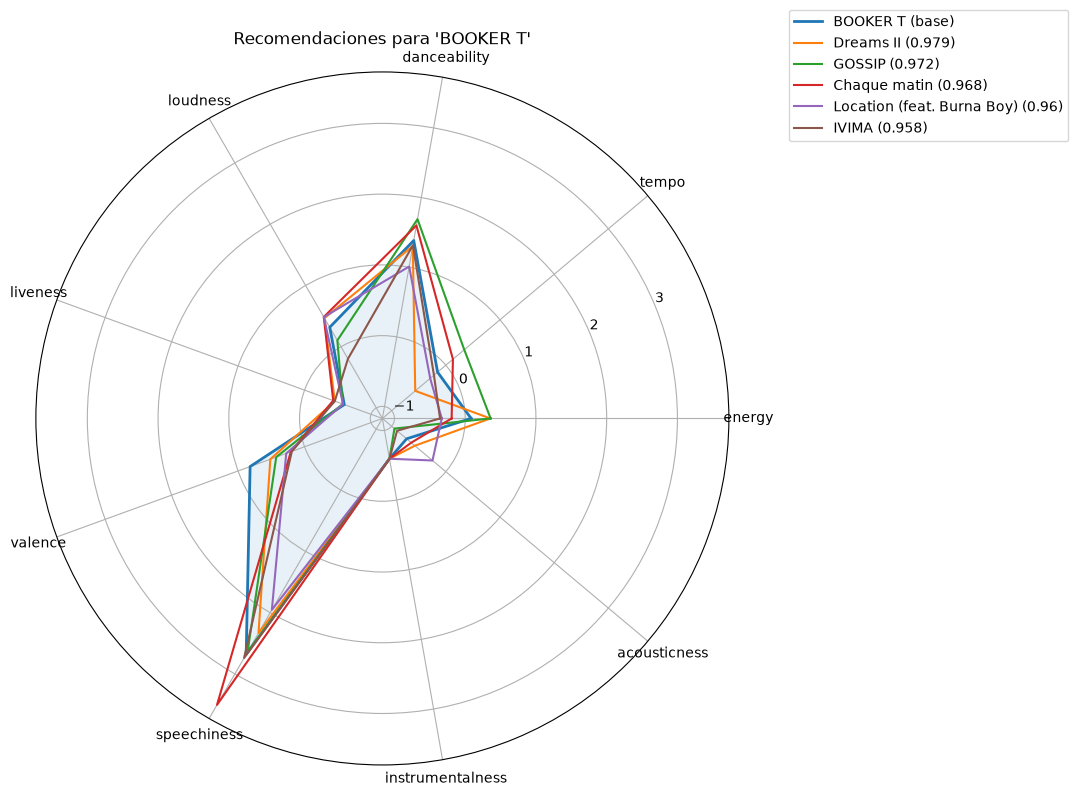

In [26]:
plot_recomendaciones(CANCION, recs)

In [27]:
df_clean.to_csv(f"{DATA_DIR}/spotify_clean.csv", index=False)